In [12]:
import os
import sys
import numpy as np
from pathlib import Path
from datetime import datetime, timedelta, timezone

from Legacy.Binance_new import Binance # Get_Price_Data_By_Time

# import importlib
# import RL_Trade_POC_Util

# # Reload the module
# importlib.reload(RL_Trade_POC_Util)

from RL_Trade_POC_Util import normalize, get_level, get_change, get_volatility, plot_array, plot_array1, plot_arrays

In [13]:
bn = Binance.instantiate(connect=False)

In [14]:
# Get_Price_Data_By_Time function seamlessly collects/creates price candles from Binance.
datatype = "klines" # "aggTrades" #, "klines"
symbol = "BTCUSDT"      # Any pair listed on Binance.

# dates that worked
# start = datetime(2018, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
# end = datetime(2026, 3, 26) # + timedelta(minutes=100)     # Any datetime

start = datetime(2026, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
end = datetime(2026, 2, 26) # + timedelta(minutes=100)     # Any datetime

interval = '1m'    # in '1m', '3m', '5m', '15m', '30m', '1h', '2h', '4h', '6h', '8h', '12h', '1d'.  (excludes: '3d', '1w')
print(f"interval: {interval}")
#------------------------------------------------------------------------------------------------------------------
candles, nFills, successful, _, reason = bn.Get_Price_Data_By_Time(datatype, symbol, interval, start, end)
print(reason)
if successful:          # price is a numpy array.
    print("\n Successful !!!!!!!!!! (nCandles, nAttributes) = {}, nCreated = {}".format(candles.shape, nFills))

interval: 1m
nCreated/nTotal/expected 0/80640/80640. 
Returning 10 columns: O H L C V, Quote V, nTrades, Buy base V, Buy quote V, Mark (0: original not forged)


 Successful !!!!!!!!!! (nCandles, nAttributes) = (80640, 10), nCreated = 0


In [15]:
n = 500

x = candles[:n, 3]      # close
v = candles[:n, 4]      # volume
x_normal = normalize(x, axis=0) * 2
v_normal = normalize(v, axis=0) * 2
back = 30           # we look back as far as 'back'

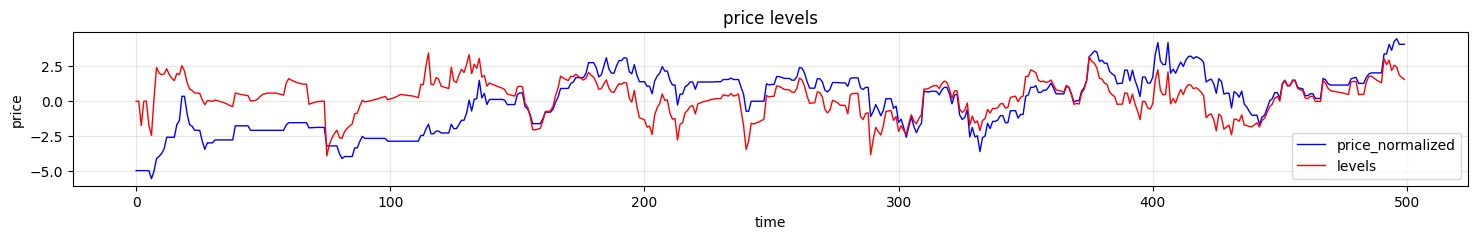

In [16]:

levels = []
for anchor in range(x.shape[0]):
    level = get_level(x, anchor, back, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([x_normal, levels], labels=['price_normalized', 'levels'], title="price levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

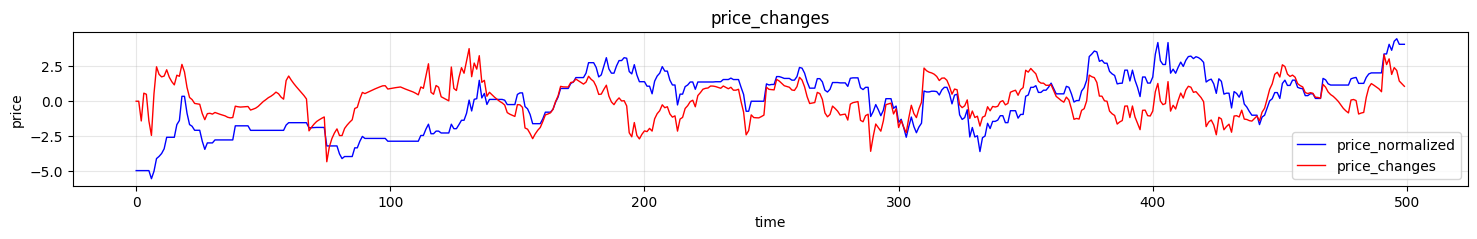

In [17]:
price_changes = []
for anchor in range(x.shape[0]):
    pc = get_change(x, anchor, back, axis=0)
    price_changes.append(pc)
price_changes = np.array(price_changes)
assert price_changes.shape == x.shape

plot_arrays([x_normal, price_changes], labels=['price_normalized', 'price_changes'], title="price_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


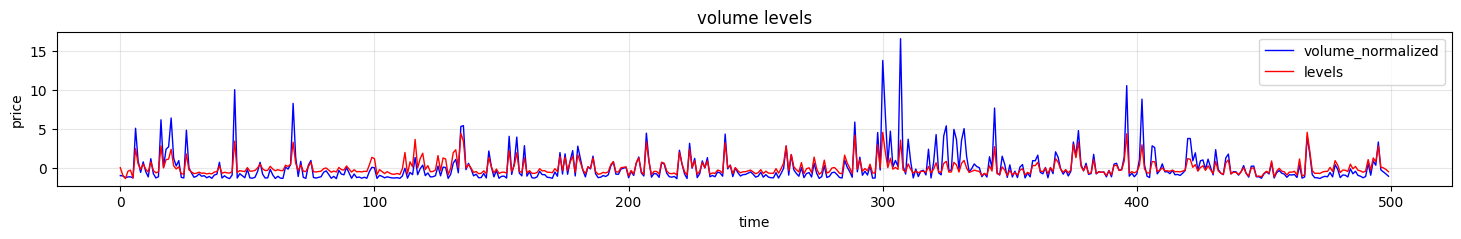

In [18]:
levels = []
for anchor in range(x.shape[0]):
    level = get_level(v, anchor, back, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([v_normal, levels], labels=['volume_normalized', 'levels'], title="volume levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

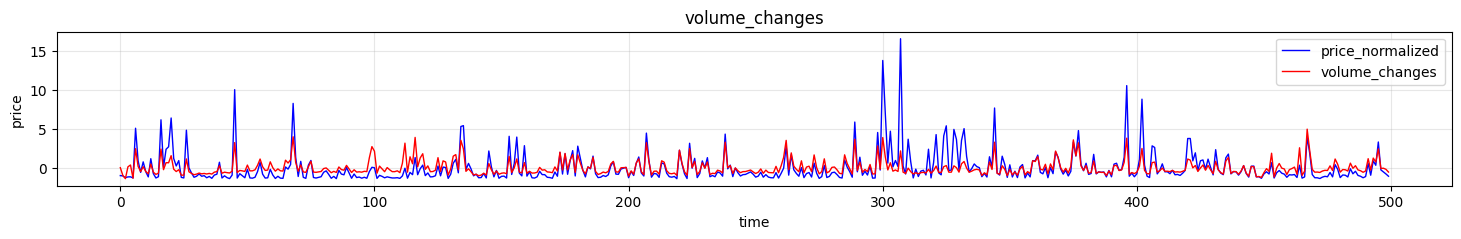

In [19]:
volume_changes = []
for anchor in range(v.shape[0]):
    vc = get_change(v, anchor, back, axis=0)
    volume_changes.append(vc)
volume_changes = np.array(volume_changes)
assert volume_changes.shape == v.shape

plot_arrays([v_normal, volume_changes], labels=['price_normalized', 'volume_changes'], title="volume_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


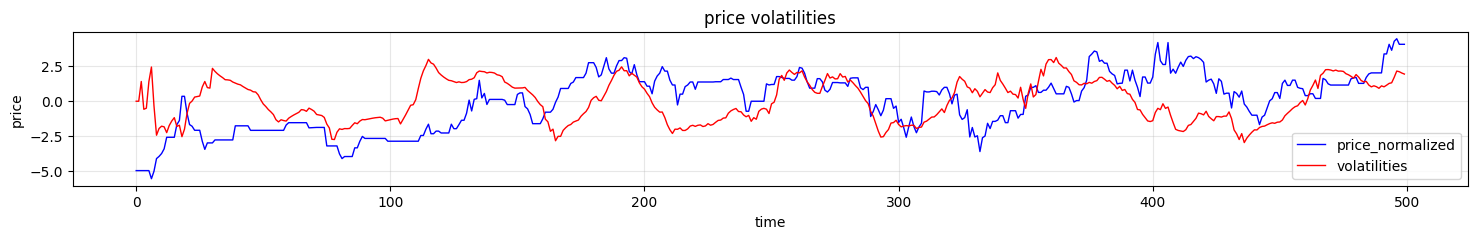

In [20]:
volatilities = []
for anchor in range(x.shape[0]):
    volatility = get_volatility(x, anchor, back, axis=0, span=back)
    volatilities.append(volatility)
volatilities = np.array(volatilities)
assert volatilities.shape == x.shape

plot_arrays([x_normal, volatilities], labels=['price_normalized', 'volatilities'], title="price volatilities", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


In [21]:
from enum import Enum

class Action(Enum):
    Buy = 'Buy'
    Hold = 'Hold'
    Sell = 'Sell'
    
max_buys = 10
max_price_history = 60
    
def get_reward(action, price_curr, buy_costs):
    would_sell_revenue = len(buy_costs) * price_curr
    total_cost = sum(buy_costs)
    would_sell_profit = would_sell_revenue - total_cost
    # print(f"would_sell_profit {would_sell_profit}")
    sell_reward = -1 if len(buy_costs) == 0 else (-1 if would_sell_profit <= 0 else 1)      # -1 if would_sell_profit <= 0 ---- think of fees
    dict = { Action.Buy: 0, Action.Hold: 0, Action.Sell: sell_reward}
    reward = dict[action]
    return reward

def get_state(prices, volumes, buy_costs):
    state = prices[- max_price_history :].tolist()     #----------------------- Consider introducing compressed history. No need to flip.
    state.append(get_level(prices, len(prices)-1, back, axis=0))
    state.append(get_change(prices, len(prices)-1, back, axis=0))
    state.append(get_level(volumes, len(prices)-1, back, axis=0))
    state.append(get_change(volumes, len(prices)-1, back, axis=0))
    state.append(get_volatility(prices, len(prices)-1, back, span=back))
    state = state + buy_costs + [0 for _ in range(max_buys - len(buy_costs))]
    state = np.array(state)
    return state

def act(action, prices, volumes, buy_costs):
    price_curr = prices[-1]
    reward = get_reward(action, price_curr, buy_costs)
    state = get_state(prices, volumes, buy_costs)
    done = action == Action.Sell

    cash_in, cash_out = 0, 0
    if action == Action.Buy:
        if len(buy_costs) < max_buys:
            cash_out += price_curr
            buy_costs.append(cash_out)
    elif action == Action.Sell:
        cash_in += len(buy_costs) * price_curr
        buy_costs = []
    
    assert cash_in <= 0 or cash_out <= 0
    
    net_cash_in = cash_in - cash_out
    
    return state, reward, done, buy_costs, net_cash_in

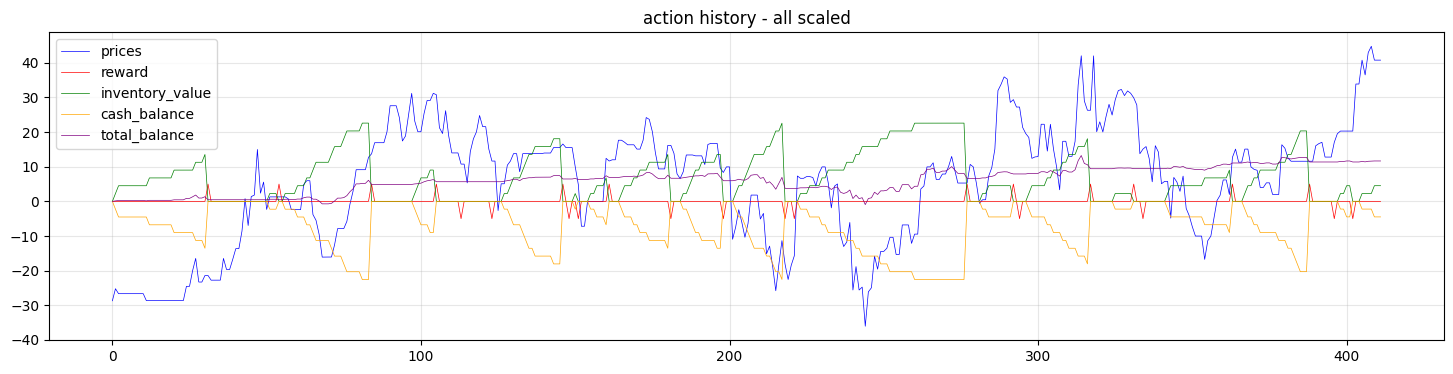

In [34]:
import random

buy_costs = []
actions = [Action.Buy] * 3 + [Action.Hold] * 10 + [Action.Sell] * 1

reward_history = []
inventory_value_history = []
cash_balance_history, cash_balance = [], 0

safe_init_anchor = max(3 * back - 2, max_price_history - 1)
max_history_required = safe_init_anchor

for anchor in range(len(x)):  
    if anchor < safe_init_anchor: continue
    
    action = random.choice(actions)
    prices = x [anchor - max_history_required + 1 : anchor + 1]
    volumes = v [anchor - max_history_required + 1 : anchor + 1]
    
    price_curr = prices[-1]
    state, reward, done, buy_costs, net_cash_in = act(action, prices, volumes, buy_costs)
    reward_history.append(reward)
    inventory_value_history.append(len(buy_costs)*price_curr)
    cash_balance += net_cash_in
    cash_balance_history.append(cash_balance)
    
    # print(action, f"reward/cash_in/balance {reward}/{net_cash_in}/{cash_balance} {'positive' if cash_balance > 0 else 'nagative'}")

cash_balance_history = np.array(cash_balance_history)
cash_balance_history = cash_balance_history / cash_balance_history.std() * 7

inventory_value_history = np.array(inventory_value_history)
inventory_value_history = inventory_value_history/inventory_value_history.std() * 7

total_balance_history = (cash_balance_history + inventory_value_history) * 300
    
arrays = [x_normal[safe_init_anchor : ] * 10, np.array(reward_history) * 5, inventory_value_history, cash_balance_history, total_balance_history]
labels = ['prices', 'reward', 'inventory_value', 'cash_balance', 'total_balance']
length = len(x_normal[safe_init_anchor : ])
for arr in arrays: assert len(arr) == length
plot_arrays(arrays, labels, title="action history - all scaled", xlabel="", ylabel="", figsize=(18, 4), flip=False, lw=0.5)